### 01. Setup

In [81]:
import os
from pathlib import Path
import random
import copy

from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import nn
import torch.optim as optim
from torchinfo import summary

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from src.dataset import create_dataloaders
from src.CNN_model_definitions import create_tiny_model, create_middle_model, create_ibm_model

#### Reproducibility seeds

In [2]:
def set_seed(seed: int = 42) -> None:
    """Seed Python, NumPy, and PyTorch (CPU & all GPUs) and
    make cuDNN run in deterministic mode."""
    # ---- Python and NumPy -------------------------------------------
    random.seed(seed)
    np.random.seed(seed)

    # ---- PyTorch (CPU  &  GPU) --------------------------------------
    torch.manual_seed(seed)            
    torch.cuda.manual_seed_all(seed)   

    # ---- cuDNN: force repeatable convolutions -----------------------
    torch.backends.cudnn.deterministic = True 
    torch.backends.cudnn.benchmark     = False

In [3]:
set_seed(15)

PyTorch offsets each worker’s seed by default, injecting new randomness. For reproducible results, you want workers to start from **fixed** seeds so every data-augmentation decision (flip, crop, colour-jitter) is repeatable across runs. The `worker_init_fn` function re-seeds Python, NumPy, and PyTorch CPU random-number generators inside **each** worker using a simple deterministic formula (`SEED + worker_id`).  The result will be identical batches, identical gradients, and identical model checkpoints, run after run.

In [4]:
# To start using this add worker_init_fn=worker_init_fn_ 
# to the definition of the dataloaders in dataset.py

def worker_init_fn_(worker_id: int) -> None:
    """Re-seed each DataLoader worker so their RNGs don't collide."""
    worker_seed = 42 + worker_id
    np.random.seed(worker_seed) 
    random.seed(worker_seed)
    torch.manual_seed(worker_seed)

#### Hyperparameters and device

In [61]:
img_size = 64
batch_size = 32
lr = 0.001
epochs = 20 
num_classes = 2 # number of classes in the dataset

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device used is {device}")

Device used is cuda


In [52]:
models_dir = Path("./models")
models_dir.mkdir(exist_ok=True)

### 01. Create the dataloaders

In [11]:
train_loader, val_loader, test_loader = create_dataloaders(batch_size)

In [12]:
images, labels = next(iter(train_loader))

print(f"Images batch shape: {images.shape}") 
print(f"Labels batch shape: {labels.shape}")


Images batch shape: torch.Size([32, 3, 64, 64])
Labels batch shape: torch.Size([32])


### 02. Import the models

In [62]:
tiny_model = create_tiny_model().to(device)
middle_model = create_middle_model().to(device)
ibm_model = create_ibm_model().to(device)


models = [tiny_model, middle_model, ibm_model]

In [63]:
for i,model in enumerate(models):
    print(f'\n Model {i+1}')
    print(summary(model, input_size=(32, 3, 64, 64)))


 Model 1
Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [32, 2]                   --
├─Conv2d: 1-1                            [32, 16, 64, 64]          448
├─BatchNorm2d: 1-2                       [32, 16, 64, 64]          32
├─ReLU: 1-3                              [32, 16, 64, 64]          --
├─MaxPool2d: 1-4                         [32, 16, 32, 32]          --
├─Conv2d: 1-5                            [32, 32, 32, 32]          4,640
├─BatchNorm2d: 1-6                       [32, 32, 32, 32]          64
├─ReLU: 1-7                              [32, 32, 32, 32]          --
├─MaxPool2d: 1-8                         [32, 32, 16, 16]          --
├─Conv2d: 1-9                            [32, 64, 16, 16]          18,496
├─BatchNorm2d: 1-10                      [32, 64, 16, 16]          128
├─ReLU: 1-11                             [32, 64, 16, 16]          --
├─MaxPool2d: 1-12                        [32, 64, 8, 8]           

In [64]:
criterion = nn.CrossEntropyLoss()

optimizers = [optim.Adam(model.parameters(), lr=lr) for model in models]


In [65]:
best_loss = [float("inf") for _ in models]
best_weights = [None for _ in models]
history = [ {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "epoch_time": []
    } for _ in models]

In [66]:
for epoch in range(epochs):

    print(f"\n{'='*60}")
    print(f"Epoch {epoch + 1}/{epochs}")
    print(f"{'='*60}")

    for model in models:
        model.train()

    # Running metrics
    train_loss_sum = [0.0 for _ in models]

    train_correct = [0 for _ in models]

    train_total = 0

    # --------------------------------------------------
    # TRAINING: one loader -> same augmented batch for all models
    # --------------------------------------------------

    progress = tqdm(
        train_loader,
        desc=f"Training epoch {epoch + 1}/{epochs}"
    )

    for images, labels in progress:

        # Move the SAME batch to the device once
        images = images.to(device)
        labels = labels.to(device)

        batch_size_actual = labels.size(0)

        for i, (model, optimizer) in enumerate(zip(models, optimizers)):
            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            # Accumulate sample-weighted loss
            train_loss_sum[i] += (
                loss.item() * batch_size_actual
            )

            preds = torch.argmax(outputs, dim=1)

            train_correct[i] += (
                preds == labels
            ).sum().item()
                        
        train_total += batch_size_actual

 
    # End of training epoch
    train_metrics = [None for _ in models]
    for i in range(len(models)):
        train_metrics[i] =  {
            "loss": train_loss_sum[i] / train_total,
            "acc": train_correct[i] / train_total
        }


    # --------------------------------------------------
    # VALIDATION: same validation data for all models
    # --------------------------------------------------

    for model in models:
        model.eval()

    val_loss_sum = [0.0 for _ in models]
    val_correct = [0 for _ in models]

    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            batch_size_actual = labels.size(0)

            for i, model in enumerate(models):
                outputs = model(images)
                loss = criterion(outputs,labels)

                val_loss_sum[i] += (
                    loss.item() * batch_size_actual
                )

                preds = torch.argmax(outputs, dim=1)

                val_correct[i] += (
                    preds == labels
                ).sum().item()
            val_total += batch_size_actual

        # End of validation epoch
        val_metrics = [None for _ in models]
        for i in range(len(models)):
            val_metrics[i] =  {
                "loss": val_loss_sum[i] / val_total,
                "acc": val_correct[i] / val_total
            }

    # --------------------------------------------------
    # SAVE METRICS AND BEST CHECKPOINTS
    # --------------------------------------------------

    for i, model in enumerate(models):
        
        history[i]["train_loss"].append(
            train_metrics[i]["loss"]
        )

        history[i]["train_acc"].append(
            train_metrics[i]["acc"]
        )

        history[i]["val_loss"].append(
            val_metrics[i]["loss"]
        )

        history[i]["val_acc"].append(
            val_metrics[i]["acc"]
        )

        # Save best model according to validation loss
        if val_metrics[i]["loss"] < best_loss[i]:

            best_loss[i] = val_metrics[i]["loss"]

            best_weights[i] = copy.deepcopy(
                model.state_dict()
            )

            torch.save(
                best_weights[i],
                models_dir /f"cnn_{i}_best.pth"
            )

    # --------------------------------------------------
    # PRINT RESULTS
    # --------------------------------------------------

    for i in range(len(models)):

        print(f"\n Model{i}:")

        print(
            f"  Train Loss: {train_metrics[i]['loss']:.4f}"
            f" | Val Loss: {val_metrics[i]['loss']:.4f}"
        )

        print(
            f"  Train Acc:  {train_metrics[i]['acc']:.4f}"
            f" | Val Acc:  {val_metrics[i]['acc']:.4f}"
        )




Epoch 1/20


Training epoch 1/20: 100% 132/132 [00:20<00:00,  6.49it/s]



 Model0:
  Train Loss: 0.0147 | Val Loss: 0.0023
  Train Acc:  0.9943 | Val Acc:  0.9989

 Model1:
  Train Loss: 0.0163 | Val Loss: 0.0003
  Train Acc:  0.9943 | Val Acc:  1.0000

 Model2:
  Train Loss: 0.0303 | Val Loss: 0.0249
  Train Acc:  0.9924 | Val Acc:  0.9889

Epoch 2/20


Training epoch 2/20: 100% 132/132 [00:20<00:00,  6.49it/s]



 Model0:
  Train Loss: 0.0141 | Val Loss: 0.0007
  Train Acc:  0.9938 | Val Acc:  1.0000

 Model1:
  Train Loss: 0.0143 | Val Loss: 0.0011
  Train Acc:  0.9945 | Val Acc:  1.0000

 Model2:
  Train Loss: 0.0404 | Val Loss: 0.0958
  Train Acc:  0.9881 | Val Acc:  0.9722

Epoch 3/20


...


 Model0:
  Train Loss: 0.0102 | Val Loss: 0.0016
  Train Acc:  0.9969 | Val Acc:  1.0000

 Model1:
  Train Loss: 0.0094 | Val Loss: 0.0015
  Train Acc:  0.9962 | Val Acc:  1.0000

 Model2:
  Train Loss: 0.0129 | Val Loss: 0.0042
  Train Acc:  0.9950 | Val Acc:  1.0000

Epoch 19/20


Training epoch 19/20: 100% 132/132 [00:20<00:00,  6.30it/s]



 Model0:
  Train Loss: 0.0068 | Val Loss: 0.0016
  Train Acc:  0.9974 | Val Acc:  0.9989

 Model1:
  Train Loss: 0.0129 | Val Loss: 0.0009
  Train Acc:  0.9952 | Val Acc:  1.0000

 Model2:
  Train Loss: 0.0172 | Val Loss: 0.0039
  Train Acc:  0.9945 | Val Acc:  0.9989

Epoch 20/20


Training epoch 20/20: 100% 132/132 [00:21<00:00,  6.19it/s]



 Model0:
  Train Loss: 0.0109 | Val Loss: 0.0004
  Train Acc:  0.9950 | Val Acc:  1.0000

 Model1:
  Train Loss: 0.0128 | Val Loss: 0.0017
  Train Acc:  0.9950 | Val Acc:  1.0000

 Model2:
  Train Loss: 0.0170 | Val Loss: 0.0040
  Train Acc:  0.9936 | Val Acc:  0.9989


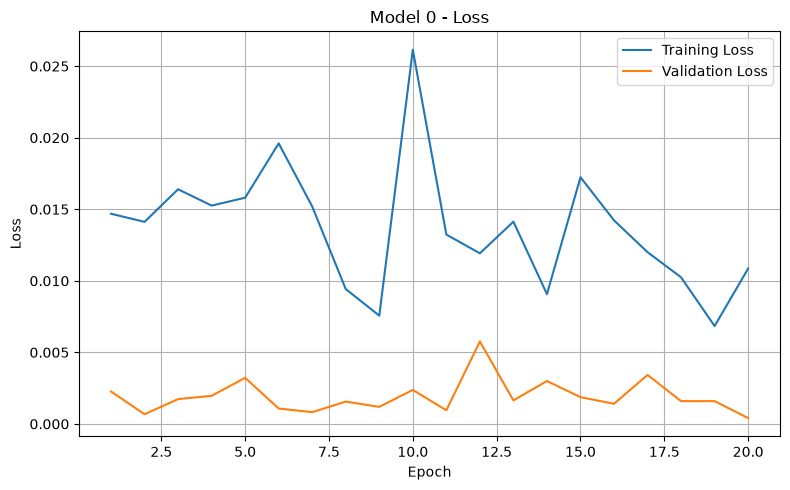

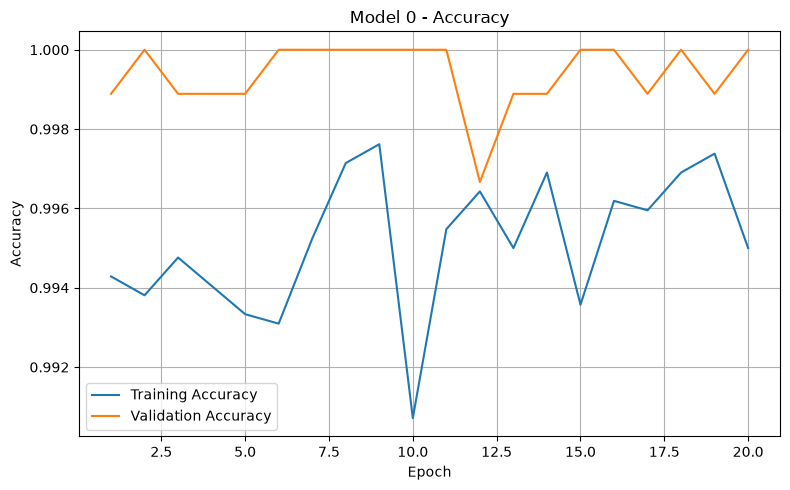

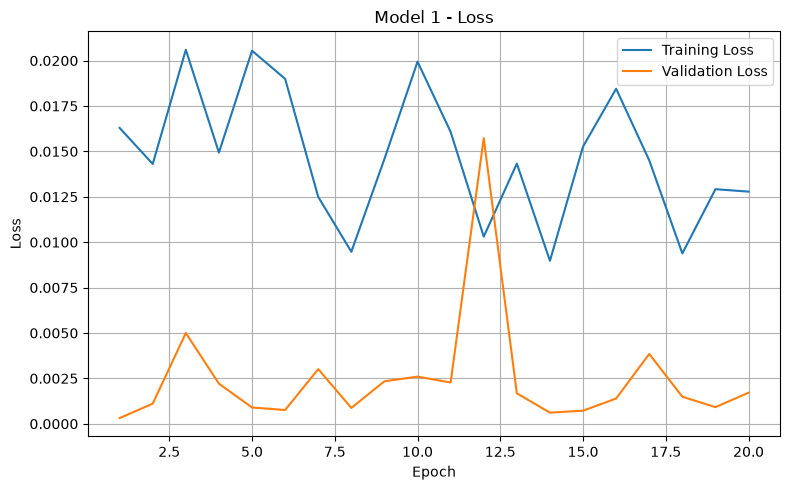

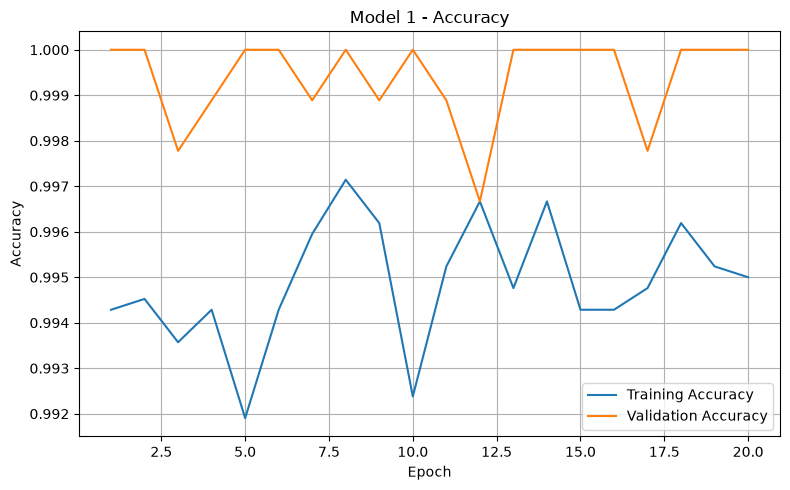

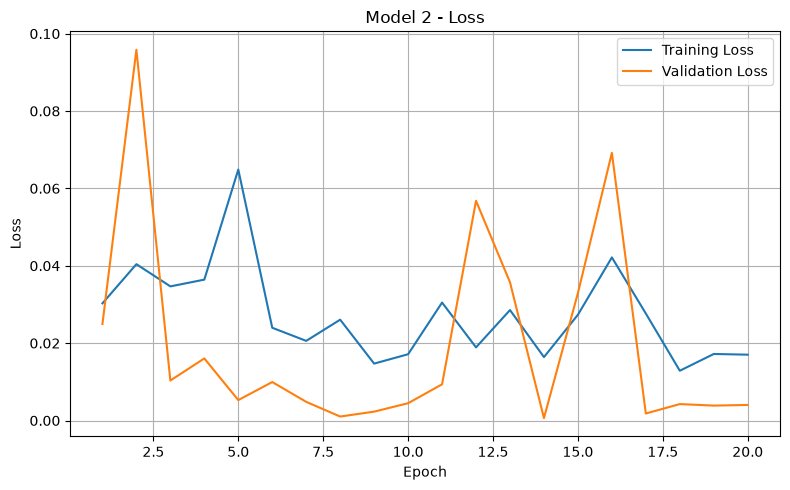

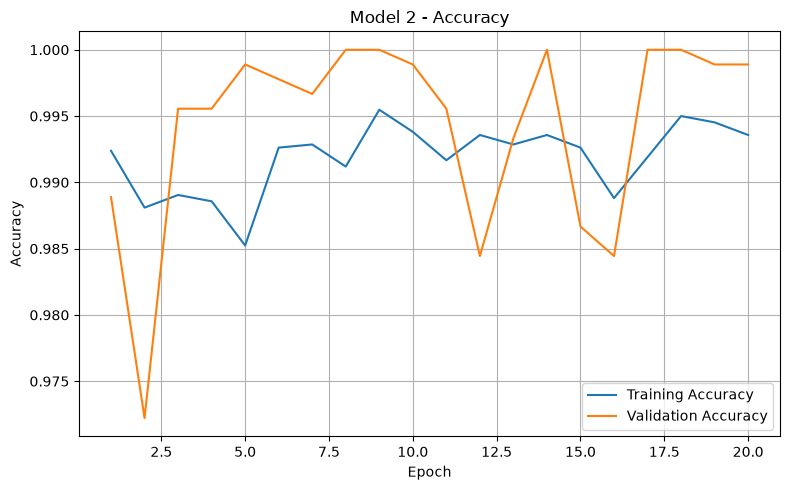

In [67]:
# Plot the training histories

for i, model in enumerate(models):

    epochs_range = range(1, len(history[i]["train_loss"]) + 1)

    # Loss
    plt.figure(figsize=(8, 5))
    plt.plot(
        epochs_range,
        history[i]["train_loss"],
        label="Training Loss"
    )
    plt.plot(
        epochs_range,
        history[i]["val_loss"],
        label="Validation Loss"
    )
    plt.title(f"Model {i} - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Accuracy
    plt.figure(figsize=(8, 5))
    plt.plot(
        epochs_range,
        history[i]["train_acc"],
        label="Training Accuracy"
    )
    plt.plot(
        epochs_range,
        history[i]["val_acc"],
        label="Validation Accuracy"
    )
    plt.title(f"Model {i} - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [82]:
for i, model in enumerate(models):
    checkpoint_path = models_dir / f"cnn_{i}_best.pth"

    model.load_state_dict(
        torch.load(checkpoint_path, map_location=device)
    )

    model.to(device)
    model.eval()

    print(f"Loaded best weights for Model {i}")

Loaded best weights for Model 0
Loaded best weights for Model 1
Loaded best weights for Model 2


In [83]:
test_results = []

for i, model in enumerate(models):

    model.eval()

    all_labels = []
    all_preds = []

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            preds = torch.argmax(outputs, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)

    test_results.append({
        "labels": all_labels,
        "preds": all_preds
    })

    accuracy = (all_preds == all_labels).mean()

    print(f"Model {i} test accuracy: {accuracy:.4f}")

Model 0 test accuracy: 0.9967
Model 1 test accuracy: 0.9956
Model 2 test accuracy: 0.9922


In [84]:
for i, result in enumerate(test_results):

    print("=" * 60)
    print(f"Model {i} - Classification Report")
    print("=" * 60)

    print(
        classification_report(
            result["labels"],
            result["preds"],
            digits=4
        )
    )

Model 0 - Classification Report
              precision    recall  f1-score   support

           0     0.9934    1.0000    0.9967       450
           1     1.0000    0.9933    0.9967       450

    accuracy                         0.9967       900
   macro avg     0.9967    0.9967    0.9967       900
weighted avg     0.9967    0.9967    0.9967       900

Model 1 - Classification Report
              precision    recall  f1-score   support

           0     0.9956    0.9956    0.9956       450
           1     0.9956    0.9956    0.9956       450

    accuracy                         0.9956       900
   macro avg     0.9956    0.9956    0.9956       900
weighted avg     0.9956    0.9956    0.9956       900

Model 2 - Classification Report
              precision    recall  f1-score   support

           0     0.9890    0.9956    0.9922       450
           1     0.9955    0.9889    0.9922       450

    accuracy                         0.9922       900
   macro avg     0.9922    0.992

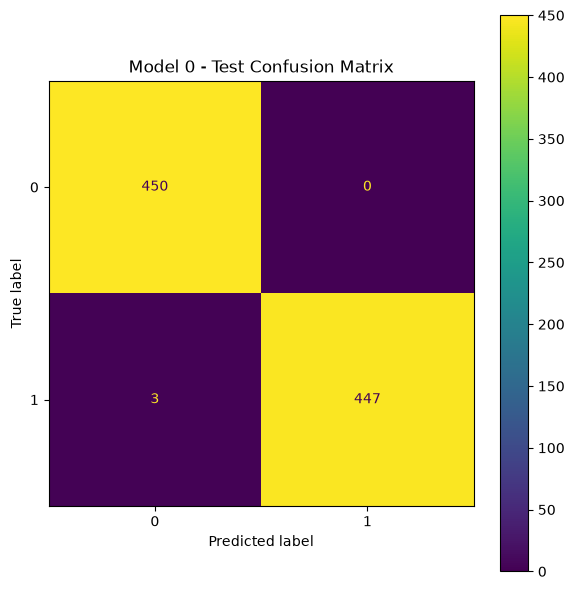

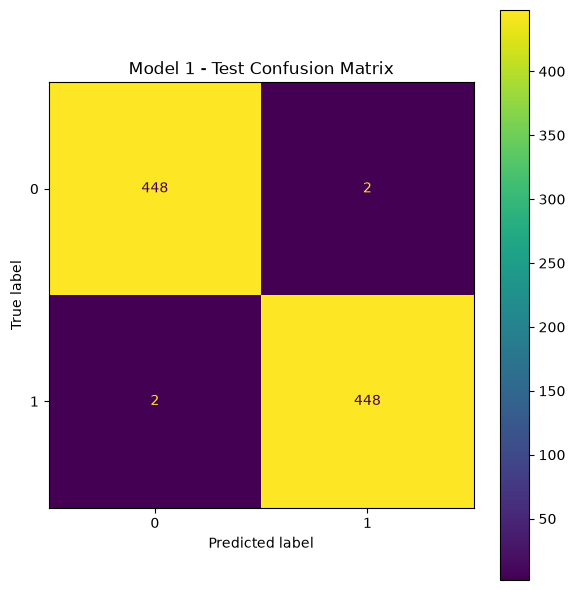

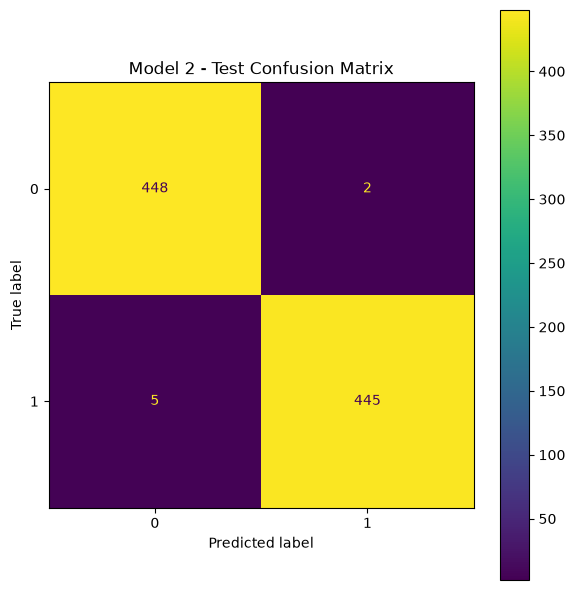

In [85]:
for i, result in enumerate(test_results):

    cm = confusion_matrix(
        result["labels"],
        result["preds"]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        #display_labels=class_names
    )

    fig, ax = plt.subplots(figsize=(6, 6))

    disp.plot(
        ax=ax,
        values_format="d"
    )

    ax.set_title(f"Model {i} - Test Confusion Matrix")

    plt.tight_layout()
    plt.show()

### Model 0 is not only by far the smallest, but has actually misclassified the least test images. We therefore chose ti at the champion model for this class and transform it to ONNX format.